This template contains pre filled code. be careful: the code is *not always correct* and certainly not *complete*.<br>

if you see this symbol:<br>
🚀 Exercise:<br>

that means, there is something more to do for you.

make sure to run all the code cells from top to bottom and check if your notebook still works after resetting the python runtime regularly **at least before you save and submit your work**!

In [514]:
# Import the necessary libraries:
import pandas as pd

# 1. Data Transformation

In [515]:
RawStudentDatasetName = "StudentData26" #use the correct dataset name of your student data input file - without file ending!!!

In [516]:
df = pd.read_csv(RawStudentDatasetName+".csv", sep=";", decimal=".") # change sep and decimal according to your data format



In [517]:
#remove intermedeate header and empty submissions:
#drop rows with index 23, 59 and 60: n.b.: these are not row numbers but index!
df = df.drop([23, 59, 60])


## 1.1 Data Cleaning

### Rename columns for better readability

In [518]:
df = df.rename(columns={"How old are you?": "age",
                            "How far do you currently live from Campus Hagenberg? (in km)": "distance",
                            "How are you coming to Hagenberg?": "transportation",
                            "How long does it take you on average to get from your current home to Hagenberg? (in min)": "duration",
                            "How good do you rate your creative skills?": "creative skills",
                            "What languages do you speak? Use a comma to separate several languages.": "languages",
                            "List one of your favorite hobbies!": "hobbies"
                        })
df

,age,distance,transportation,duration,creative skills,languages,hobbies
0,20,11,Car,11,4,German; English; Romanian; Italian,Drawing
1,21,200km,car,140,3,german; english; polish,work out
2,23,30km,bus; train,40,4,german; english; vietnamese,crochet; gaming; sewing; reading; doom scrolling
3,19,178,Zug,300,4,Deutsch; Englisch; Spanisch,Geschichte lernen
4,19,0,bus; train,130,4,German; Italian; English,listening to music
...,...,...,...,...,...,...,...
70,20,30,Bus,50 m,4,"Englisch, Spanish",Videogames
71,20,0.1,Walking,5,4,"Albanian, English",playing the violin
72,19,0.01,I live in the dorm in Hagenberg,3,4,"Serbian, English, a little German",painting
73,21,3,Car,5,3,"German,English",working out


🚀 Exercise: Correction of redundant values or typing errors.<br>
some examples are already there. Scan the data if this is sufficient and change/remove/replace/add your own.

In [519]:
# Remove unnecessary text characters and blanks:
df["distance"] = df["distance"].str.replace('km','',regex=True)
df["distance"] = df["distance"].str.replace('-','',regex=True)
df["distance"] = df["distance"].str.replace('50m','0.05')
df["distance"] = df["distance"].str.replace('0.8 meters','0.0008')
df["distance"] = df["distance"].str.strip()

df.loc[df.distance.str.contains("31.J�n", regex=False), 'distance'] = '31.1' #what???
df.loc[df.distance.str.contains("10;500", regex=False), 'distance'] = '10500' #idk?

#replace 'wrong' units
df["duration"] = df["duration"].str.replace(', because i already live in hagenberg','', regex=True)
df["duration"] = df["duration"].str.replace('min','', regex=True)
df["duration"] = df["duration"].str.replace('m','', regex=True)
df["duration"] = df["duration"].str.replace(r'\+','', regex=True)
df["duration"] = df["duration"].str.replace('5h','300')
df["duration"] = df["duration"].str.replace('3h 30','210')
df["duration"] = df["duration"].str.strip()
df.loc[df.duration.str.contains("1;800", regex=False), 'duration'] = '1800' #probably BSing so im assuming 18 minutes and 10.5km idk


#Consistant Capitalisation of Languages:
df["languages"] = df["languages"].str.replace('english','English')
df["languages"] = df["languages"].str.replace('polish','Polish')
df["languages"] = df["languages"].str.replace('german','German')
df["languages"] = df["languages"].str.replace('spanish','Spanish')

#remove language levels:
df["languages"] = df["languages"].str.replace('A2','')
df["languages"] = df["languages"].str.replace('A1.1','')

#treat Languages in parentheses as own entries:
df["languages"] = df["languages"].str.replace('(','')
df["languages"] = df["languages"].str.replace(')','')

#remove leading and trailing whitespace:
df["languages"] = df["languages"].str.strip()

#replace excel artefact ("31.Jän") - needs to be string, because datatypes are not yet converted!
#55 is no row number, but index!
#df.at[55, 'distance'] = "31.1"

df.loc[df.transportation.str.contains("-"), 'transportation'] = 'on foot'
df = df.fillna(value="on foot")


#remove ambiquious lines e.g. "'1h (Car); 2h 15 (Bus + Train)" - alternative: split into 2 separate lines
df = df.drop([5,10, 16, 52, 53])



In [520]:
#don't do that, if you are not sure about the usage of . or , in your values!
df["distance"] = df["distance"].str.replace(',','.', regex=True)
df["duration"] = df["duration"].str.replace(',','.', regex=True)


In [521]:
# show remaining "-" or nan values
mask = df.isna() | (df == '-')
df[mask.any(axis=1)]

,age,distance,transportation,duration,creative skills,languages,hobbies


In [522]:
#delete 54: no useful dist/transport info - would still have hobbies and age etc. so open for discussion.
df = df.drop([54])

#assume 72 is walking (1 minute, 0.05km distance)
df.at[72,'transportation'] = "Walk"


### Adjusting the data types


 🚀 Exercise: Many data types exist as strings (objects). To use quantative and temporal data for visualization, these must first be converted:

In [523]:
#Data include a mix of decimal points (",", ".")!
# Filter rows where ANY cell contains ','
mask = df[["distance","duration"]].apply(lambda row: row.str.contains(r'[,]').any(), axis=1)
df[mask]

,age,distance,transportation,duration,creative skills,languages,hobbies


In [524]:
#8: distance: 10,500, duration:1,800 -> 10.5km in 1.8 minutes is not plausible. Transportation: plane -> , is for 1000 digit 
#df.at[8,'distance'] = "10500"
#df.at[8,'duration'] = "1800"

In [525]:
#convert data to correct types
df.age = df.age.astype(int)
df.distance = df.distance.astype(float)
df.duration = df.duration.astype(float)

## 2.2 Granularity and derivation of new attributes

### Changing the granularity of a date format

The attribute types can also be subsequently modified (e.g. converting quantitative data into ordinal classes) if this helps to answer the questions.
The DateTime format alone offers numerous options for expressing dates as years, weeks, days, hours, etc.
This [page](https://pandas.pydata.org/docs/user_guide/timeseries.html#time-date-components) gives an overview of possible options, such as `year`, `month`, `day`, `hour`, `minute`, `second`, `date`, `time`, `timetz`, `dayofyear`, `weekofyear`.

For example, Timestamp can be converted to the date:

In [526]:
#df["Timestamp"].dt.date

### Conversion of quantitative attributes into ordinal classes

One method is to use `loc` to access certain defined areas and define ordinal categories:

In [527]:
df.loc[df['distance'].between(df['distance'].min(), 10, 'both'), 'distance_cat'] = 'near'
df.loc[df['distance'].between(10, 20, 'right'), 'distance_cat'] = 'medium'
df.loc[df['distance'].between(20, 100, 'right'), 'distance_cat'] = 'far'
df.loc[df['distance'].between(100, df['distance'].max(), 'right'), 'distance_cat'] = 'far far away'

Convert integer (presented as string) to Likert scale meaning

In [528]:
mapping = {
    "1": "not really",
    "2": "some",
    "3": "medium",
    "4": "good",
    "5": "very good"
}

df["Creativity"] = df["creative skills"].map(mapping)

### Derive other values from data

In [529]:
#calculate average speed
df["speed"] = df["distance"] / (df["duration"]/60)

### Combine transportation method into a few meaningful categories

In [530]:
#show distinquish values of transportation:
df.transportation.unique()

<StringArray>
[                                            'Car',
                                             'car',
                                      'bus; train',
                                             'Zug',
                                         'by foot',
                                            'Auto',
                          'car; plane; train; bus',
                                     'train & bus',
                                     'Car / Hotel',
                                            'Legs',
                                     'walky walky',
                                         'walking',
                                          'by car',
                                          'by bus',
 'with a combination of several public transports',
                                        'by train',
                                'Public Transport',
                                             'bus',
                                         'on foot'

In [531]:
#capitalization of each word:
df.transportation = df.transportation.str.title()

#remove "by "...
df["transportation"] = df["transportation"].str.replace('By ','', regex=True)

#show:
df.transportation.unique()

<StringArray>
[                                            'Car',
                                      'Bus; Train',
                                             'Zug',
                                            'Foot',
                                            'Auto',
                          'Car; Plane; Train; Bus',
                                     'Train & Bus',
                                     'Car / Hotel',
                                            'Legs',
                                     'Walky Walky',
                                         'Walking',
                                             'Bus',
 'With A Combination Of Several Public Transports',
                                           'Train',
                                'Public Transport',
                                         'On Foot',
                                    'Bus Or Train',
                             'I Live In Hagenberg',
                               'Walking From Dorm'

In [532]:
#it's a mix of german, english, capitalization mixes etc.
#translate to english:
df["transportation"] = df["transportation"].str.replace('Zug','Train')
df["transportation"] = df["transportation"].str.replace('Auto','Car')

#combine Live in Hagenberg and similar, assume walking:
df["transportation"] = df["transportation"].str.replace('I Live In Hagenberg','Walk')
df["transportation"] = df["transportation"].str.replace('I Live In Hagenberg... Haha','Walk')
df["transportation"] = df["transportation"].str.replace('I Live In The Dorm In Hagenberg','Walk')

#walking has many different names...
df["transportation"] = df["transportation"].str.replace('To Foot','Walk')
df["transportation"] = df["transportation"].str.replace('Walky Walky','Walk')
df["transportation"] = df["transportation"].str.replace('Legs','Walk')
df["transportation"] = df["transportation"].str.replace('Foot','Walk')
df["transportation"] = df["transportation"].str.replace('Walking','Walk')
df["transportation"] = df["transportation"].str.replace('Walk... Haha','Walk')
df["transportation"] = df["transportation"].str.replace('Walk From Dorm','Walk')
df["transportation"] = df["transportation"].str.replace('Walking From Dorm','Walk')
df["transportation"] = df["transportation"].str.replace('Because I Am A Exchange Student','Walk')

#assume long distance car - have a look at raw data, if assumption is correct!
df["transportation"] = df["transportation"].str.replace('Car / Hotel','Car')


#these simplifications are open to discussion:
df["transportation"] = df["transportation"].str.replace('With A Combination Of Several Public Transports','Mix')
df["transportation"] = df["transportation"].str.replace('Bus; Train','Mix')
df["transportation"] = df["transportation"].str.replace('Car; Plane; Train; Bus','Mix')
df["transportation"] = df["transportation"].str.replace('Bus Or Train','Mix')
df["transportation"] = df["transportation"].str.replace('Train & Bus','Mix')

#also open to discussion:
df["transportation"] = df["transportation"].str.replace('Public Transport','Mix')

In [533]:
df.transportation.unique()

<StringArray>
['Car', 'Mix', 'Train', 'Walk', 'Bus', 'On Walk']
Length: 6, dtype: str

### Export cleanded dataset

In [534]:
# export csv
df.to_csv(RawStudentDatasetName+"_cleaned.csv", index=False)    #By setting index=False the row index labels are not saved in the spreadsheet

# 2. Visualization of the dataset

 🚀 For the following exercises make sure that:

 🔳 Each chart is correctly annotated (Title, Axes, Legend, Units)
 
 🔳 Use correct data types (nominal, ordinal, quantitative) and corresponding visual channels (see lecture notes)
 
 🔳 Categories are sorted meaningfully if necessary

In [535]:
import altair as alt
import seaborn as sns

🚀 Exercise: create a scatterplot to correlate distance and duration with Altair. Use color to encode the means of transportation!

In [536]:
chart = alt.Chart(df).mark_circle().encode(
    x="duration",
    y="distance",
    color="transportation:N"
)
chart

alt.Chart(...)

In [537]:
#better log scale: but it doesn't work!
chart = alt.Chart(df).mark_circle().encode(
    x=alt.X("distance", scale=alt.Scale(type="log")),
    y=alt.Y("duration", scale=alt.Scale(type="log")),
    color="transportation:N"
)
chart


alt.Chart(...)

In [538]:
#because of log(0) is undef.
df.loc[df['duration'] < 1, 'duration'] = 1
df.loc[df['distance'] < 0.01, 'distance'] = 0.01


In [539]:
#have a look at speed
#df["speed"].describe()

In [540]:
#max: inf speed???
#-> because speed is dist/duration -> if duration is 0 -> speed is inf.!
#calc again (we have set dist/duration before to plausible values)

#calculate average speed
df["speed"] = df["distance"] / (df["duration"]/60)


In [541]:
chart = alt.Chart(df).mark_circle().encode(
    x=alt.X("distance", scale=alt.Scale(type="log")),
    y=alt.Y("duration", scale=alt.Scale(type="log")),
    color="transportation:N"
)
chart

alt.Chart(...)

#### can you find "Speedy Gonzales" and "The Snail"?

In [542]:
df.speed.describe()

count     66.000000
mean      25.814600
std       47.995325
min        0.004615
25%        0.600000
50%        7.750000
75%       36.000000
max      350.000000
Name: speed, dtype: float64

In [543]:
#max speed of 350? have a look:
df[df["speed"]==350]

,age,distance,transportation,duration,creative skills,languages,hobbies,distance_cat,Creativity,speed
8,19,10500.0,Mix,1800.0,2,Spanish; German; English,sleeping; watching series,far far away,some,350.0


In [544]:
df.sort_values("speed", ascending=True)

,age,distance,transportation,duration,creative skills,languages,hobbies,distance_cat,Creativity,speed
4,19,0.01,Mix,130.0,4,German; Italian; English,listening to music,near,good,0.004615
28,20,0.20,Bus,240.0,1,"German, English","horse riding, riding motorbike, gaming, sleeping",near,not really,0.050000
24,19,0.01,Walk,3.0,3,"English, Romanian, Russian",Driving car,near,medium,0.200000
72,19,0.01,Walk,3.0,4,"Serbian, English, a little German",painting,near,good,0.200000
20,19,0.01,Walk,2.0,3,"Russian, Uzbek, German, Turkish, English",Sleeping,near,medium,0.300000
...,...,...,...,...,...,...,...,...,...,...
12,33,221.00,Car,162.0,4,German; English; Japanese,Beeing Creative!,far far away,good,81.851852
22,20,25.00,Car,18.0,3,"English, German, Hungarian",Video games,far,medium,83.333333
1,21,200.00,Car,140.0,3,German; English; Polish,work out,far far away,medium,85.714286
11,20,345.00,Car,210.0,2,German; English,Dancing,far far away,some,98.571429


In [545]:
#350 km/h for 10.5 km distance ??? not plausible!

🚀 Exercise: Instead of using a nominal color channel use an ordered color scheme and visualize the ordered distance categories in a scatterplot in altair:

In [546]:
chart = alt.Chart(df).mark_circle().encode(
    x=alt.X("distance", scale=alt.Scale(type="log")),
    y=alt.Y("duration", scale=alt.Scale(type="log")),
    color="distance_cat:O"
)
chart

alt.Chart(...)

🚀 Exercise: Use an quantitative color scheme in a scatterplot in altair:

In [547]:
chart = alt.Chart(df).mark_circle().encode(
    x=alt.X("distance", scale=alt.Scale(type="log")),
    y=alt.Y("duration", scale=alt.Scale(type="log")),
    color="age:Q"
)
chart

alt.Chart(...)

🚀 Exercise: create a scatterplot to correlate distance and duration with Seaborn. Use color to encode the means of transportation!

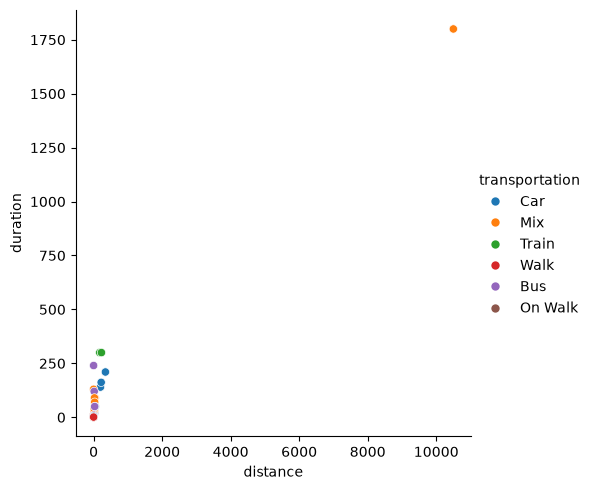

In [548]:
sns.relplot(x="distance", y="duration", data=df, kind="scatter", hue="transportation");


🚀 Exercise: Instead of using a nominal color channel use an ordered color scheme and visualize the ordered distance categories in a scatterplot in seaborn:

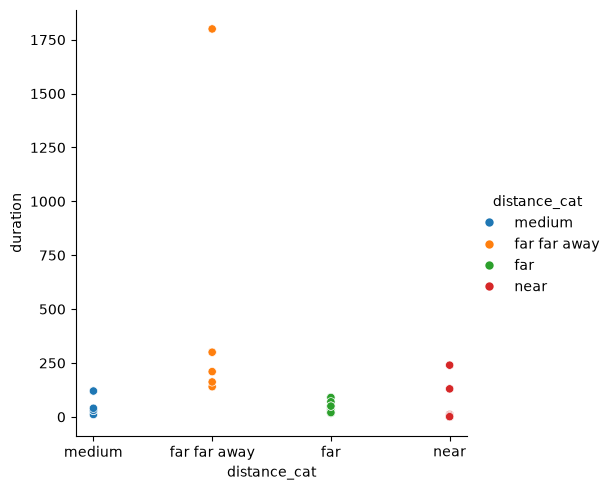

In [549]:
sns.relplot(x="distance_cat", y="duration", data=df, kind="scatter", hue="distance_cat");


🚀 Exercise: create a bar chart with Altair and visualize the means of transportation on the y-axis and the average age on the x-axis, sort by age:

In [550]:
alt.Chart(df).mark_bar(color='firebrick').encode(
    alt.X('average(age)'),
    alt.Y('transportation:N', sort='x')
)

alt.Chart(...)

🚀 Exercise: create a bar chart with Seaborn and visualize the means of transportation on the y-axis and the average age on the x-axis, sort by age:

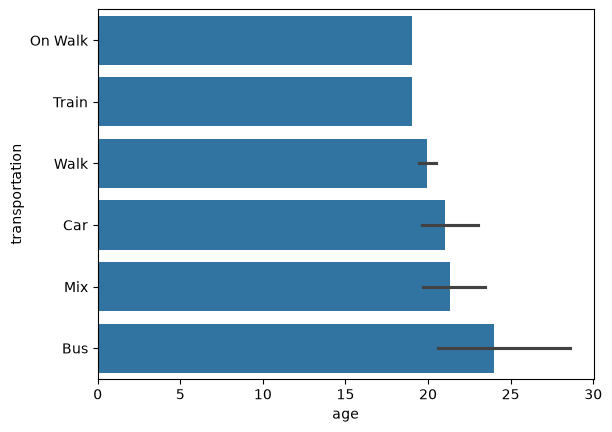

In [551]:
import numpy as np
sns.barplot(y="transportation", x="age", data=df, estimator=np.mean, order=df.groupby('transportation')['age'].mean().sort_values(ascending=True).index);